# 01 — Eksplorasi Data Awal (Data Exploration)

---
### 1. Setup Environment


In [3]:
import os
import sys
from pathlib import Path

ROOT_DIR = Path(r"c:\Project\napasloka\napasloka")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))


---
### 2. Pemuatan Modul & Pembacaan Dataset


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils.config import load_yaml_config

# Memuat konfigurasi stasiun
locations_cfg = load_yaml_config("locations.yaml").get("locations", [])
print(f"Total stasiun terkonfigurasi: {len(locations_cfg)} stasiun")

# Membaca dataset terproses
df_co = pd.read_csv(ROOT_DIR / "data" / "processed" / "jabodetabek_co_dataset.csv")
df_co2 = pd.read_csv(ROOT_DIR / "data" / "processed" / "jabodetabek_co2_dataset.csv")

# Standardisasi waktu
df_co["datetime"] = pd.to_datetime(df_co["datetime"], utc=True).dt.tz_convert("Asia/Jakarta")
df_co2["datetime"] = pd.to_datetime(df_co2["datetime"], utc=True).dt.tz_convert("Asia/Jakarta")

print(f"Dataset CO  : {len(df_co):,} baris | Rentang: {df_co['datetime'].min()} s.d. {df_co['datetime'].max()}")
print(f"Dataset CO₂ : {len(df_co2):,} baris | Rentang: {df_co2['datetime'].min()} s.d. {df_co2['datetime'].max()}")


Total stasiun terkonfigurasi: 15 stasiun
Dataset CO  : 233,175 baris | Rentang: 2024-10-26 07:00:00+07:00 s.d. 2026-08-04 23:00:00+07:00
Dataset CO₂ : 233,175 baris | Rentang: 2024-10-26 07:00:00+07:00 s.d. 2026-08-04 23:00:00+07:00


---
### 3. Pemeriksaan Missing Values & Kelengkapan Data


In [7]:
print("Missing Values Dataset CO")
print(df_co.isnull().sum())

print("Missing Values Dataset CO2")
print(df_co2.isnull().sum())

# Pemeriksaan jumlah baris per lokasi pengamatan
stasiun_counts = df_co.groupby("location").size()
print(f"Jumlah observasi per lokasi pengamatan (CO): {stasiun_counts.unique().tolist()} baris per lokasi")

Missing Values Dataset CO
location                0
latitude                0
longitude               0
datetime                0
temperature_2m          0
relative_humidity_2m    0
rain                    0
wind_speed_100m         0
carbon_monoxide         0
dtype: int64
Missing Values Dataset CO2
location                0
latitude                0
longitude               0
datetime                0
temperature_2m          0
relative_humidity_2m    0
rain                    0
wind_speed_100m         0
carbon_dioxide          0
dtype: int64
Jumlah observasi per lokasi pengamatan (CO): [15545] baris per lokasi


---
### 4. Statistik Deskriptif Konsentrasi Polutan & Cuaca


In [8]:
cols_co = ["carbon_monoxide", "temperature_2m", "relative_humidity_2m", "rain", "wind_speed_100m"]
display(df_co[cols_co].describe().round(2))

cols_co2 = ["carbon_dioxide", "temperature_2m", "relative_humidity_2m", "rain", "wind_speed_100m"]
display(df_co2[cols_co2].describe().round(2))


,carbon_monoxide,temperature_2m,relative_humidity_2m,rain,wind_speed_100m
count,233175.0,233175.00,233175.00,233175.00,233175.00
mean,1670.8,27.05,80.24,0.33,11.58
std,1465.7,2.69,13.54,1.14,6.37
min,0.0,18.90,19.99,0.00,0.00
25%,686.0,24.95,71.86,0.00,6.79
50%,1220.0,26.46,83.75,0.00,10.56
75%,2157.0,28.90,90.86,0.10,15.38
max,19559.0,37.90,100.00,27.60,45.28


,carbon_dioxide,temperature_2m,relative_humidity_2m,rain,wind_speed_100m
count,233175.00,233175.00,233175.00,233175.00,233175.00
mean,462.74,27.05,80.24,0.33,11.58
std,20.25,2.69,13.54,1.14,6.37
min,422.00,18.90,19.99,0.00,0.00
25%,449.00,24.95,71.86,0.00,6.79
50%,457.00,26.46,83.75,0.00,10.56
75%,472.00,28.90,90.86,0.10,15.38
max,631.00,37.90,100.00,27.60,45.28


---
### 5. Visualisasi Distribusi & Korelasi Polutan


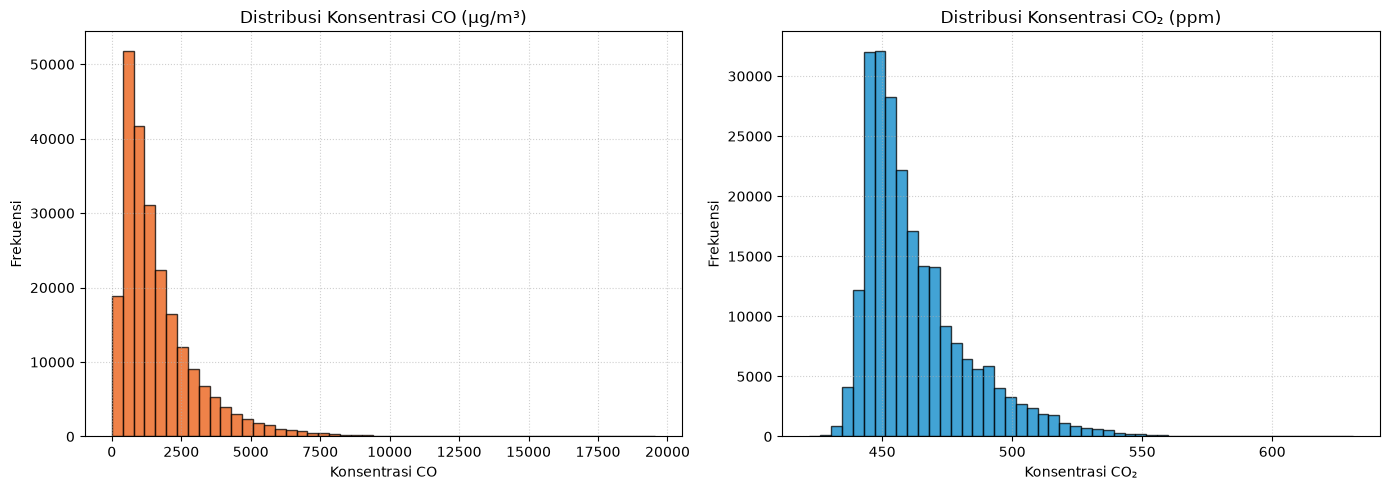

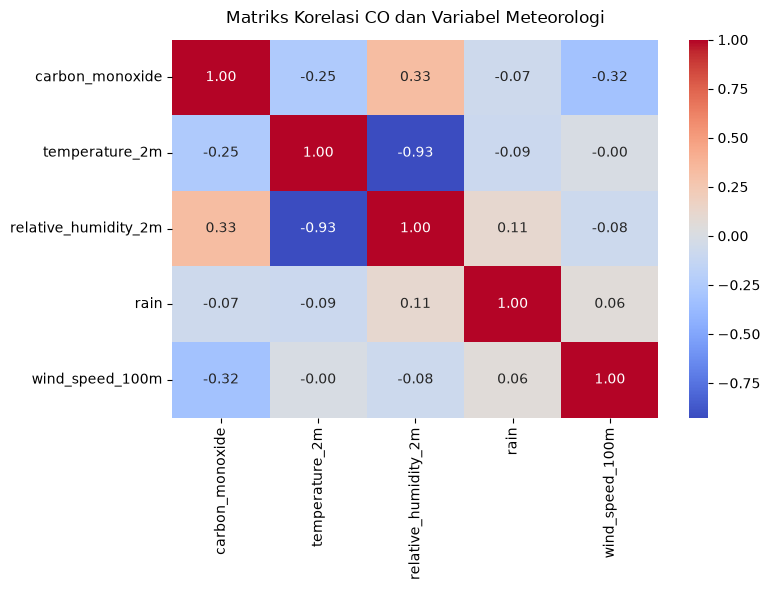

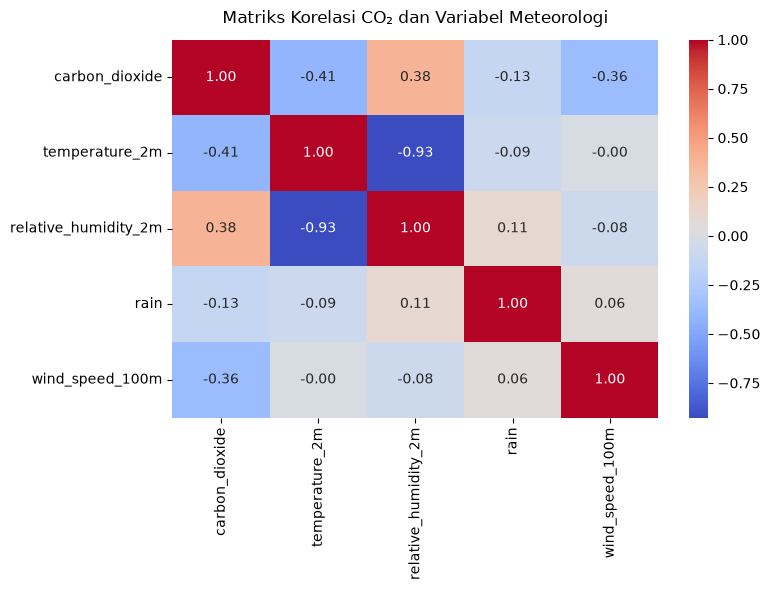

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi CO
axes[0].hist(df_co["carbon_monoxide"].dropna(), bins=50, color="#ea580c", alpha=0.75, edgecolor="black")
axes[0].set_title("Distribusi Konsentrasi CO (µg/m³)", fontsize=12)
axes[0].set_xlabel("Konsentrasi CO")
axes[0].set_ylabel("Frekuensi")
axes[0].grid(True, linestyle=":", alpha=0.6)

# Distribusi CO2
axes[1].hist(df_co2["carbon_dioxide"].dropna(), bins=50, color="#0284c7", alpha=0.75, edgecolor="black")
axes[1].set_title("Distribusi Konsentrasi CO₂ (ppm)", fontsize=12)
axes[1].set_xlabel("Konsentrasi CO₂")
axes[1].set_ylabel("Frekuensi")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# Heatmap Korelasi Meteorologi terhadap CO
plt.figure(figsize=(8, 6))
corr = df_co[cols_co].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Matriks Korelasi CO dan Variabel Meteorologi", fontsize=12, pad=12)
plt.tight_layout()
plt.show()


# Heatmap Korelasi Meteorologi terhadap CO2
plt.figure(figsize=(8, 6))
corr = df_co2[cols_co2].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Matriks Korelasi CO₂ dan Variabel Meteorologi", fontsize=12, pad=12)
plt.tight_layout()
plt.show()
